# 02 · Who will churn? Trained on February, tested once on March

The plan ([`reports/kkbox_analysis_plan.md`](../reports/kkbox_analysis_plan.md)) fixes the
design: models are chosen and tuned on the February 2017 cohort only, then scored once on the
March 2017 cohort, the situation a deployed model faces. The March labels are read in one cell,
section 3, and nothing is changed after it.

- **Candidates:** a rule (churn if auto-renew is off or the latest payment was a cancellation),
  logistic regression, and LightGBM.
- **Primary metric:** PR-AUC on March (churn is rare, about 6%), plus ROC-AUC, Brier score,
  calibration and the share of churners in the top 5/10/20%.
- **Which model ships:** LightGBM only if its March PR-AUC beats logistic regression with a
  paired bootstrap interval that excludes zero.

| | |
|---|---|
| **Question** | Which members will churn next month? Trained on February 2017 and tested once on March, the way a deployed model is used. |
| **Answer** | LightGBM ships: PR-AUC 0.594 on March against a 9.0% base rate, clearly ahead of logistic regression (0.506) and a simple rule (0.321). Its top 10% of scores hold 60% of the members who churned. Its probabilities run low when churn rises, so calibration needs a monthly check. |
| **Next** | [Notebook 03](03_kkbox_listening.ipynb) tests whether listening data adds anything. |

In [1]:
import os
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold, train_test_split

from src import records
from src.churn.model import Prep, calibration_table, metrics, paired_bootstrap_pr_auc
from src.data import kkbox

con, SOURCE = kkbox.connect()
fdir = kkbox.features_dir(SOURCE)
feb = pd.read_parquet(fdir / "feb.parquet").merge(kkbox.labels(con, "feb"), on="msno")
mar = pd.read_parquet(fdir / "mar.parquet")
BOOT = int(os.environ.get("KKBOX_BOOT", "1000"))
SEED = 20261101
print(f"source: {SOURCE}; February {len(feb):,} members ({feb['is_churn'].mean():.2%} churn); March {len(mar):,} members")

source: real; February 992,931 members (6.39% churn); March 970,960 members


## 1. Tuning inside February

20% of February is set aside for the calibration decision; tuning uses 5-fold
cross-validation on the other 80%.

In [2]:
fit_df, cal_df = train_test_split(feb, test_size=0.2, stratify=feb["is_churn"], random_state=SEED)
prep = Prep().fit(fit_df)
Xl_fit, scale = prep.linear(fit_df)
Xt_fit = prep.trees(fit_df)
y_fit = fit_df["is_churn"].to_numpy()
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xl_fit, y_fit))

LR_GRID = [0.01, 0.1, 1.0]
GBM_GRID = [dict(num_leaves=31, min_child_samples=200), dict(num_leaves=63, min_child_samples=200),
            dict(num_leaves=127, min_child_samples=500), dict(num_leaves=255, min_child_samples=1000)]
GBM_BASE = dict(n_estimators=400, learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                reg_lambda=1.0, n_jobs=2, verbose=-1, random_state=SEED)


def cv_score(make, X):
    s = []
    for tr, va in folds:
        m = make().fit(X.iloc[tr] if hasattr(X, "iloc") else X[tr], y_fit[tr])
        s.append(average_precision_score(y_fit[va], m.predict_proba(X.iloc[va] if hasattr(X, "iloc") else X[va])[:, 1]))
    return float(np.mean(s))


cv = []
for C in LR_GRID:
    cv.append({"model": "logistic", "params": {"C": C},
               "cv_pr_auc": cv_score(lambda C=C: LogisticRegression(C=C, max_iter=500), Xl_fit)})
for g in GBM_GRID:
    cv.append({"model": "lightgbm", "params": g,
               "cv_pr_auc": cv_score(lambda g=g: lgb.LGBMClassifier(**GBM_BASE, **g), Xt_fit)})
cv = pd.DataFrame(cv)
best = cv.loc[cv.groupby("model")["cv_pr_auc"].idxmax()].set_index("model")
print(best)
cv.round(4)

                                                params  cv_pr_auc
model                                                            
lightgbm  {'num_leaves': 31, 'min_child_samples': 200}   0.574781
logistic                                    {'C': 0.1}   0.434842


,model,params,cv_pr_auc
0,logistic,{'C': 0.01},0.4339
1,logistic,{'C': 0.1},0.4348
2,logistic,{'C': 1.0},0.4348
3,lightgbm,"{'num_leaves': 31, 'min_child_samples': 200}",0.5748
4,lightgbm,"{'num_leaves': 63, 'min_child_samples': 200}",0.5746
5,lightgbm,"{'num_leaves': 127, 'min_child_samples': 500}",0.5717
6,lightgbm,"{'num_leaves': 255, 'min_child_samples': 1000}",0.5683


## 2. Final models and the calibration decision

Each model is refitted on the 80%. Isotonic calibration is kept only if it lowers the Brier
score on the held-out 20% when fitted and scored on different halves of it.

In [3]:
lr = LogisticRegression(C=best.loc["logistic", "params"]["C"], max_iter=500).fit(Xl_fit, y_fit)
gbm = lgb.LGBMClassifier(**GBM_BASE, **best.loc["lightgbm", "params"]).fit(Xt_fit, y_fit)
y_cal = cal_df["is_churn"].to_numpy()
raw_cal = {"logistic": lr.predict_proba(prep.linear(cal_df, scale)[0])[:, 1],
           "lightgbm": gbm.predict_proba(prep.trees(cal_df))[:, 1]}
calibrate, iso = {}, {}
half = np.random.default_rng(SEED).random(len(y_cal)) < 0.5
for name, p in raw_cal.items():
    gain = []
    for a, b in ((half, ~half), (~half, half)):
        f = IsotonicRegression(out_of_bounds="clip").fit(p[a], y_cal[a])
        gain.append(brier_score_loss(y_cal[b], p[b]) - brier_score_loss(y_cal[b], f.predict(p[b])))
    calibrate[name] = bool(np.mean(gain) > 0)
    iso[name] = IsotonicRegression(out_of_bounds="clip").fit(p, y_cal) if calibrate[name] else None
print("isotonic calibration kept:", calibrate)


def score(name, df):
    p = lr.predict_proba(prep.linear(df, scale)[0])[:, 1] if name == "logistic" else gbm.predict_proba(prep.trees(df))[:, 1]
    return iso[name].predict(p) if iso[name] is not None else p


def rule(df):
    return ((df["auto_renew"].fillna(0) == 0) | (df["last_cancel"].fillna(0) == 1)).astype(float).to_numpy()

isotonic calibration kept: {'logistic': True, 'lightgbm': False}


## 3. The one look at March

In [4]:
mar = mar.merge(kkbox.labels(con, "mar"), on="msno")          # March labels read here, once
y_mar = mar["is_churn"].to_numpy()
p_mar = {"rule": rule(mar), "logistic": score("logistic", mar), "lightgbm": score("lightgbm", mar)}
results = pd.DataFrame({k: metrics(y_mar, v) for k, v in p_mar.items()}).T
results.loc["base rate", "pr_auc"] = y_mar.mean()
boot = paired_bootstrap_pr_auc(y_mar, p_mar["lightgbm"], p_mar["logistic"], n=BOOT, seed=SEED)
ship = "lightgbm" if boot["ci"][0] > 0 else "logistic"
print(f"March churn {y_mar.mean():.2%}. LightGBM minus logistic PR-AUC {boot['diff']:+.4f} "
      f"[{boot['ci'][0]:+.4f}, {boot['ci'][1]:+.4f}] -> ships: {ship}")
results.round(4)

March churn 8.99%. LightGBM minus logistic PR-AUC +0.0879 [+0.0857, +0.0905] -> ships: lightgbm


,pr_auc,roc_auc,brier,capture_5,capture_10,capture_20
rule,0.3212,0.7841,0.1037,0.2490,0.4978,0.6755
logistic,0.5064,0.8454,0.0594,0.3706,0.5638,0.7398
lightgbm,0.5943,0.8625,0.0544,0.4106,0.6037,0.7350
base rate,0.0899,NaN,NaN,NaN,NaN,NaN


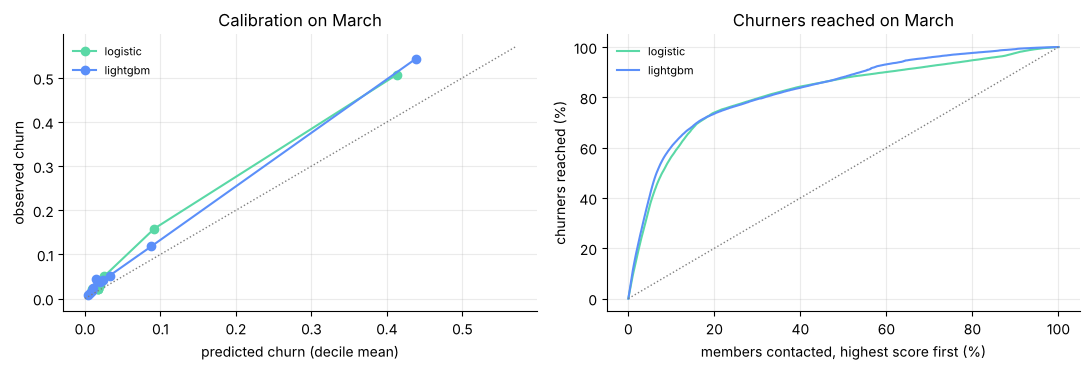

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, col in (("logistic", "#5AD8A6"), ("lightgbm", "#5B8FF9")):
    t = calibration_table(y_mar, p_mar[name])
    axes[0].plot(t["predicted"], t["observed"], "o-", color=col, label=name)
    order = np.argsort(-p_mar[name])
    axes[1].plot(np.arange(1, len(order) + 1) / len(order) * 100, np.cumsum(y_mar[order]) / y_mar.sum() * 100,
                 color=col, label=name)
lim = [0, max(axes[0].get_xlim()[1], axes[0].get_ylim()[1])]
axes[0].plot(lim, lim, ":", color="#7F7F7F", lw=1)
axes[0].set(xlabel="predicted churn (decile mean)", ylabel="observed churn", title="Calibration on March")
axes[1].plot([0, 100], [0, 100], ":", color="#7F7F7F", lw=1)
axes[1].set(xlabel="members contacted, highest score first (%)", ylabel="churners reached (%)",
            title="Churners reached on March")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "02_kkbox_churn_model.png", SOURCE)

**How to read the figure.** Left (calibration): each point is a tenth of members, grouped by predicted churn; a well-calibrated model sits on the diagonal. Points above it mean more members churned than predicted, which is what happens when churn rises from February to March. Right (gains): if you contact members from the highest score down, how many of the churners you reach. A steeper curve is a better ranking; the top 10% reaching about 60% of churners is what makes a targeted campaign affordable.

In [6]:
gain = pd.Series(gbm.booster_.feature_importance("gain"), index=Xt_fit.columns).sort_values(ascending=False)
importance = (gain / gain.sum()).head(10)
pd.DataFrame({"msno": mar["msno"], "p_churn": p_mar[ship], "is_churn": y_mar}).to_parquet(fdir / "mar_scores.parquet", index=False)
record = {"feb_members": int(len(feb)), "feb_churn": float(feb["is_churn"].mean()), "mar_members": int(len(mar)),
          "mar_churn": float(y_mar.mean()), "cv": cv.assign(params=cv["params"].astype(str)).to_dict(orient="records"),
          "chosen": {k: best.loc[k, "params"] for k in best.index}, "calibrated": calibrate,
          "march": results.drop(index="base rate").to_dict(orient="index"), "lightgbm_minus_logistic": boot,
          "ships": ship, "importance_top10": importance.to_dict()}
print("wrote", records.write("02_kkbox_churn_model", record, SOURCE).name)
m = results.loc[ship]
print(f"On March, the {ship} model reaches PR-AUC {m['pr_auc']:.3f} against a {y_mar.mean():.1%} base rate "
      f"(ROC-AUC {m['roc_auc']:.3f}); the top 10% of scores hold {m['capture_10']:.0%} of churners. "
      f"The rule reaches PR-AUC {results.loc['rule', 'pr_auc']:.3f}.")

wrote 02_kkbox_churn_model.json
On March, the lightgbm model reaches PR-AUC 0.594 against a 9.0% base rate (ROC-AUC 0.863); the top 10% of scores hold 60% of churners. The rule reaches PR-AUC 0.321.


## Takeaways

- **The model ranks well on a month it never saw:** PR-AUC 0.594, about 6.6 times the base rate.
- **LightGBM earns its place** over logistic regression by a margin whose interval excludes zero, as the plan required.
- **Watch calibration:** the ranking holds up, but predicted probabilities run low when churn rises; recalibrate monthly before using them in money calculations.

**Next:** [notebook 03](03_kkbox_listening.ipynb), does listening add anything?